![Banner](../../../../Images/Banner/07_remote_sensing/09_06_banner_rs_lidar.png)


# Large-Area LiDAR Processing: Tiling, Streaming, Parallel Work and the GPU

A single 1.5 km LiDAR tile from a modern survey holds 12 to 15 million points and half a gigabyte of data; a county holds thousands of such tiles and a national archive tens of billions of points. This notebook processes all ten USGS 3DEP tiles around Ithaca, New York (135 million points, 4.9 GB) with `geolattice.rsense.lidar`: it builds a tile index from the headers alone, streams a file in chunks, processes the tiles in parallel into seamless DEM, DSM, CHM and forest-metric mosaics, shows why tiles need overlapping buffers, and runs terrain derivatives on the GPU. It closes with the complete end-to-end LiDAR workflow that the other notebooks in this chapter cover step by step.


## Overview

### Why large-area LiDAR needs a different approach

| Problem | Consequence | Remedy |
|---|---|---|
| Memory | 15 million points with 11 attributes take 0.6 to 1.3 GB in memory depending on the data types; a few tiles exhaust a laptop | Read only the fields needed, process tile by tile, stream files in chunks |
| Run time | Ground filtering and gridding of hundreds of tiles take hours on one core | Run tiles in parallel (threads or processes), move gridding and raster operations to a GPU |
| Edges | Filters, interpolation and neighbourhood features see only one side of a tile edge, leaving seams | Process each tile with a **buffer** of neighbouring points, then trim results back to the tile core |
| Data transfer | Downloading whole archives to use a small area | Cloud-optimised formats (COPC, EPT) let readers request only a region or a level of detail |
| Bookkeeping | Many files of different ages, CRSs and densities | A tile index (footprints, point counts, CRS, density) built from the headers before any processing |

### Tiling with buffers

A **tile scheme** divides the area into a regular grid of square cores (often the delivery tiles themselves). For each core the processor reads the core plus a buffer of width $b$ on every side, runs the algorithm, and keeps only the results inside the core. The buffer must be at least as wide as the largest neighbourhood the algorithm uses: the ground filter window, the interpolation search distance, the tree-detection window. Results from neighbouring tiles then meet without seams.

### Parallel processing

Tiles are independent once they carry their own buffers, so they can run at the same time. **Threads** share memory and work well when the heavy work happens inside NumPy and SciPy, which release Python's global interpreter lock; **processes** avoid the lock entirely but must copy their inputs. The speed-up is limited by disk reading and by memory: ten tiles in parallel need ten tiles' worth of memory.

### The GPU

Many LiDAR operations are data-parallel: binning points into cells (scatter reductions for min, max, mean and count) and local raster operations such as slope, curvature or TPI apply the same arithmetic to millions of independent elements. On a GPU (with CuPy) they run tens of times faster than on one CPU core. Sequential algorithms such as priority-flood filling and flow routing stay on the CPU.

### Cloud-native archives

**COPC** stores a whole LAZ file as an octree in one file; **EPT** stores an octree of many files with a JSON description. Both let a reader ask for "points in this box at about this spacing" and download only those parts (see the fundamentals notebook). PDAL pipelines can read EPT directly from the USGS 3DEP archive on AWS, filter on the server side of the stream and write tiles locally.


## Large-Area Processing with GeoLattice


### Learning objectives

1. Build a tile index from LAS headers without reading any points.
2. Estimate memory needs and reduce them by reading only the fields required.
3. Stream a large file in chunks to compute statistics.
4. Process many tiles in parallel into seamless mosaics with `process_files` and `merge_rasters`.
5. Show the seams that unbuffered tiling creates and remove them with `process_tiles` and buffers.
6. Run terrain derivatives on the GPU and compare run times with the CPU.
7. Organise a complete LiDAR workflow from raw tiles to exported products.


### Data

| Files | Content |
|---|---|
| `Ithaca/u_*.las` (10 files, 4.9 GB) | USGS 3DEP NY Finger Lakes 2020 tiles around Ithaca, New York: 1.5 km x 1.5 km each, 12 to 15 million points per tile, LAS 1.4, UTM zone 18N with NAVD88 heights, ground (2), unclassified (1) and noise (7, 18) classified |


### Contents

1. Setup
2. A tile index from the headers
3. Memory and reading only what is needed
4. Streaming a file in chunks
5. Processing all tiles in parallel
6. Seamless mosaics
7. Edge effects and buffered tiles
8. Terrain derivatives on the GPU
9. Writing tiles
10. The end-to-end workflow
11. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

import os  # file sizes and CPU count
import time  # timing
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import rasterio  # raster I/O
import matplotlib.pyplot as plt  # figures
from shapely.geometry import box  # rectangles

import geolattice.rsense as rs  # GeoLattice remote sensing

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages
plt.rcParams.update({"figure.dpi": 110})  # figure resolution
print("geolattice.rsense", rs.__version__, "| backends available:", rs.available_backends(),  # versions and backends
      "| CPU cores:", os.cpu_count())
rs.set_backend("cpu")  # start on the CPU; the GPU section switches explicitly

geolattice.rsense 0.3.35 | backends available: ['cpu', 'cuda'] | CPU cores: 24


Backend(name='cpu', device_id=0)

In [2]:
from pathlib import Path  # file paths

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_06_lidar/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_06_lidar"), Path("../../../../Data/08_remote_sensing/08_06_lidar"))
             if p.is_dir()), None)
if DATA is None:  # neither location exists
    # stop with a clear message
    raise FileNotFoundError("Run the notebook from its own folder or from the GeoLattice repository root.")
OUT = DATA.parent / "outputs"  # folder for the products this notebook writes
OUT.mkdir(exist_ok=True)  # create it if needed

TILES = sorted((DATA / "Ithaca").glob("*.las"))  # all ten tiles
print(f"{len(TILES)} tiles, {sum(p.stat().st_size for p in TILES) / 1e9:.2f} GB")  # count and size

10 tiles, 4.91 GB


## A tile index from the headers

`rs.lidar.las_info` reads only the header of each file, so indexing 4.9 GB of tiles takes a fraction of a second. The tile index holds each tile's footprint, point count, density, elevation range and the share of points by return, and is the starting point for planning any processing.


indexed 10 tiles in 0.12 s | total 136 million points


,points,size (MB),points/m²,z min,z max,first returns,version,format
tile,,,,,,,,
u_3750069650,14748208,530.97,6.55,115.40,340.27,0.58,1.4,6
u_3750069800,11848273,426.54,5.27,108.10,265.98,0.74,1.4,6
u_3765069500,14323739,515.66,6.37,320.26,445.38,0.63,1.4,6
u_3765069650,12002154,432.08,5.33,240.95,414.19,0.70,1.4,6
u_3765069800,13924217,501.27,6.19,114.81,297.04,0.66,1.4,6
u_3780069500,14794185,532.62,6.58,250.81,446.06,0.62,1.4,6
u_3780069650,14334357,516.04,6.37,175.28,367.22,0.57,1.4,6
u_3780069800,15062245,542.24,6.69,154.26,315.16,0.62,1.4,6
u_3795069650,12936283,465.71,5.75,179.23,398.63,0.62,1.4,6


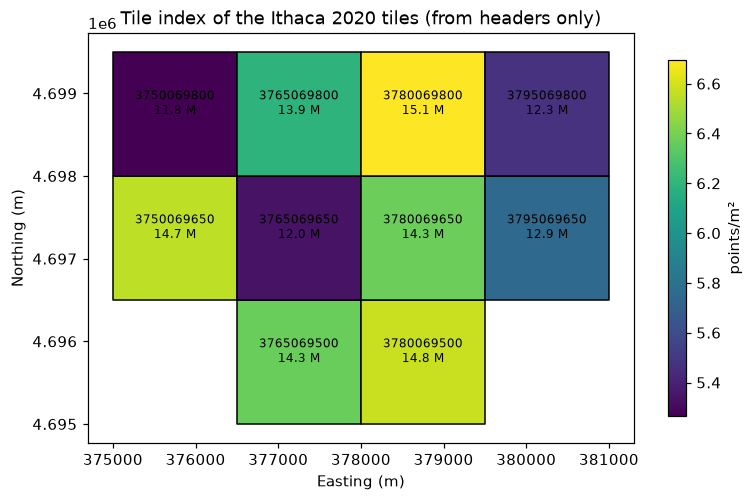

In [3]:
t0 = time.perf_counter()  # start the timer
rows = []  # one row per tile
for p in TILES:  # each file
    i = rs.lidar.las_info(p)  # header only
    xmin, ymin, xmax, ymax = i["mins"][0], i["mins"][1], i["maxs"][0], i["maxs"][1]  # footprint
    area = (xmax - xmin) * (ymax - ymin)  # m²
    rows.append({"tile": p.stem, "points": i["point_count"], "size (MB)": p.stat().st_size / 1e6,  # size
                 "points/m²": i["point_count"] / area, "z min": i["mins"][2], "z max": i["maxs"][2],  # density, heights
                 "first returns": i["points_by_return"][0] / i["point_count"],  # share of first returns (one per pulse)
                 "version": i["version"], "format": i["point_format"], "geometry": box(xmin, ymin, xmax, ymax)})
index = gpd.GeoDataFrame(rows, crs=6347).set_index("tile")  # tile index (NAD83(2011) / UTM 18N)
# summary line
print(f"indexed {len(index)} tiles in {time.perf_counter() - t0:.2f} s | total {index.points.sum() / 1e6:.0f} million points")
display(index.drop(columns="geometry").round(2))  # the index table

fig, ax = plt.subplots(figsize=(8, 6))  # one panel
index.plot(ax=ax, column="points/m²", cmap="viridis", edgecolor="black", legend=True,  # tiles coloured by density
           legend_kwds={"label": "points/m²", "shrink": 0.7})
for name, r in index.iterrows():  # label each tile
    # label each tile with its name and point count
    ax.text(r.geometry.centroid.x, r.geometry.centroid.y, f"{name[2:]}\n{r.points / 1e6:.1f} M", ha="center", fontsize=8)
# axis labels and title
ax.set(title="Tile index of the Ithaca 2020 tiles (from headers only)", xlabel="Easting (m)", ylabel="Northing (m)"); plt.show()

## Memory and reading only what is needed

A `PointCloud` keeps every attribute as a NumPy array. Reading only the fields an operation needs (`fields=`) saves memory and time: a DEM needs only x, y, z and the classification.


In [4]:
p = TILES[0]  # one tile
rows = {}  # one row per read
for label, kw in (("all fields", {}), ("classification only", {"fields": ["classification"]})):  # two reads
    t0 = time.perf_counter()  # start the timer
    pc = rs.lidar.read_las(p, **kw)  # read the tile
    sec = time.perf_counter() - t0  # time taken
    nbytes = sum(np.asarray(pc[f]).nbytes for f in pc.fields)  # memory used by the arrays
    rows[label] = {"fields": len(pc.fields), "memory (GB)": nbytes / 1e9, "seconds": sec,  # result of this read
                   "bytes per point": nbytes / len(pc)}
    del pc  # free it
pd.DataFrame(rows).T.round(2)  # show the comparison

,fields,memory (GB),seconds,bytes per point
all fields,11.0,0.62,0.56,42.0
classification only,4.0,0.37,0.42,25.0


## Streaming a file in chunks

`rs.lidar.read_las_chunks` yields a file in pieces of `chunk_size` points, so statistics can be accumulated without ever holding the whole file in memory. The cell computes the class histogram, the elevation histogram and the return structure of one tile in 2-million-point chunks.


14,748,208 points in 8 chunks, 0.8 s | returns from multi-return pulses: 70.4%
classes: {1: 8338680, 2: 6382862, 7: 26638, 18: 28}


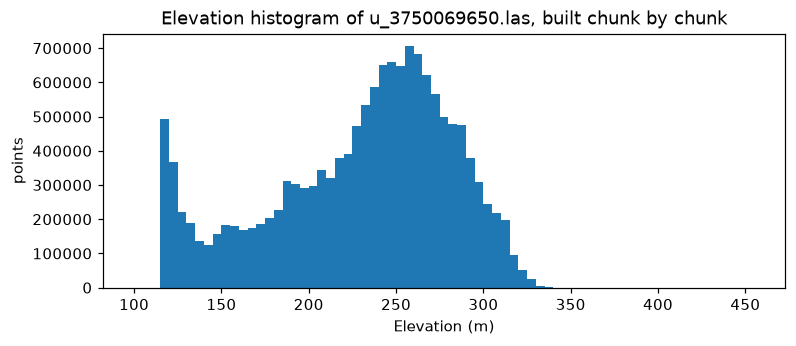

In [5]:
t0 = time.perf_counter()  # start the timer
classes, n_chunks, n_pts = pd.Series(dtype=float), 0, 0  # running class counts
zbins = np.arange(100, 460, 5)  # elevation bins (m)
zhist = np.zeros(len(zbins) - 1)  # running elevation histogram
multi = 0  # running count of returns from multi-return pulses
for chunk in rs.lidar.read_las_chunks(TILES[0], chunk_size=2_000_000,  # one chunk at a time
                                      fields=["classification", "number_of_returns"]):  # one chunk at a time
    classes = classes.add(pd.Series(np.asarray(chunk["classification"])).value_counts(), fill_value=0)  # classes
    zhist += np.histogram(np.asarray(chunk.z), bins=zbins)[0]  # elevations
    multi += int((np.asarray(chunk["number_of_returns"]) > 1).sum())  # multi-return points
    n_chunks += 1; n_pts += len(chunk)  # counters
print(f"{n_pts:,} points in {n_chunks} chunks, {time.perf_counter() - t0:.1f} s | "  # summary line
      f"returns from multi-return pulses: {multi / n_pts:.1%}")  # summary
print("classes:", classes.astype(int).to_dict())  # class counts
fig, ax = plt.subplots(figsize=(8, 3)); ax.bar(zbins[:-1], zhist, width=5, align="edge")  # elevation histogram
# axis labels and title
ax.set(xlabel="Elevation (m)", ylabel="points", title=f"Elevation histogram of {TILES[0].name}, built chunk by chunk"); plt.show()

## Processing all tiles in parallel

`rs.lidar.process_files` reads each file with `read_las` and applies a function to it, in `n_jobs` parallel threads. The function below is a small pipeline that turns one tile into the standard products on the tile's exact 1.5 km grid, so the outputs mosaic without resampling:

1. DEM at 2 m from the producer's ground points;
2. DSM at 2 m from first returns, and the CHM;
3. heights above ground and area-based forest metrics (p95 height and canopy cover) at 20 m;
4. a first-return density grid at 10 m.


In [6]:
FIELDS = ["classification", "return_number", "number_of_returns"]  # the attributes the pipeline needs

def tile_products(pc):  # one tile -> dictionary of rasters
    x0 = np.floor(pc.bbox[0] / 1500) * 1500; y0 = np.floor(pc.bbox[1] / 1500) * 1500  # tile origin (1.5 km grid)
    bounds = (x0, y0, x0 + 1500, y0 + 1500)  # exact tile extent
    pc = pc.drop_noise()  # remove noise classes 7 and 18
    dem = rs.lidar.dem(pc.ground(), 2.0, bounds=bounds)  # bare earth
    dsm = rs.lidar.dsm(pc, 2.0, bounds=bounds)  # first-return surface
    chm = rs.lidar.chm(dsm, dem)  # canopy height
    gm = rs.lidar.grid_metrics(rs.lidar.normalize_heights(pc, dem), res=20.0, metrics=("p95", "cover"))  # forest metrics
    dens = rs.lidar.density_map(pc, 10.0, first_returns=True)  # pulses per m²
    # the products of this tile
    return {"dem": dem, "dsm": dsm, "chm": chm, "p95": gm["p95"], "cover": gm["cover"], "density": dens,
            "points": len(pc)}

N_JOBS = min(5, os.cpu_count())  # tiles processed at the same time (limited by memory)
t0 = time.perf_counter()  # start the timer
results = rs.lidar.process_files(TILES, tile_products, n_jobs=N_JOBS, read_kwargs={"fields": FIELDS})  # all tiles
elapsed = time.perf_counter() - t0  # wall-clock time
n = sum(r["points"] for r in results)  # points processed
# summary line
print(f"{len(results)} tiles, {n / 1e6:.0f} million points in {elapsed:.0f} s with {N_JOBS} threads "
      f"({n / elapsed / 1e6:.2f} million points per second)")  # throughput

10 tiles, 136 million points in 87 s with 5 threads (1.57 million points per second)


## Seamless mosaics

`rs.lidar.merge_rasters` mosaics the per-tile grids. Because each tile was gridded on its own exact extent, the grids align and the mosaic needs no resampling.


dem      (2250, 3000)   cell 2 m | 83.3% filled
dsm      (2250, 3000)   cell 2 m | 83.3% filled
chm      (2250, 3000)   cell 2 m | 83.3% filled
p95      (225, 300)     cell 20 m | 82.6% filled
cover    (225, 300)     cell 20 m | 82.6% filled
density  (450, 600)     cell 10 m | 83.3% filled


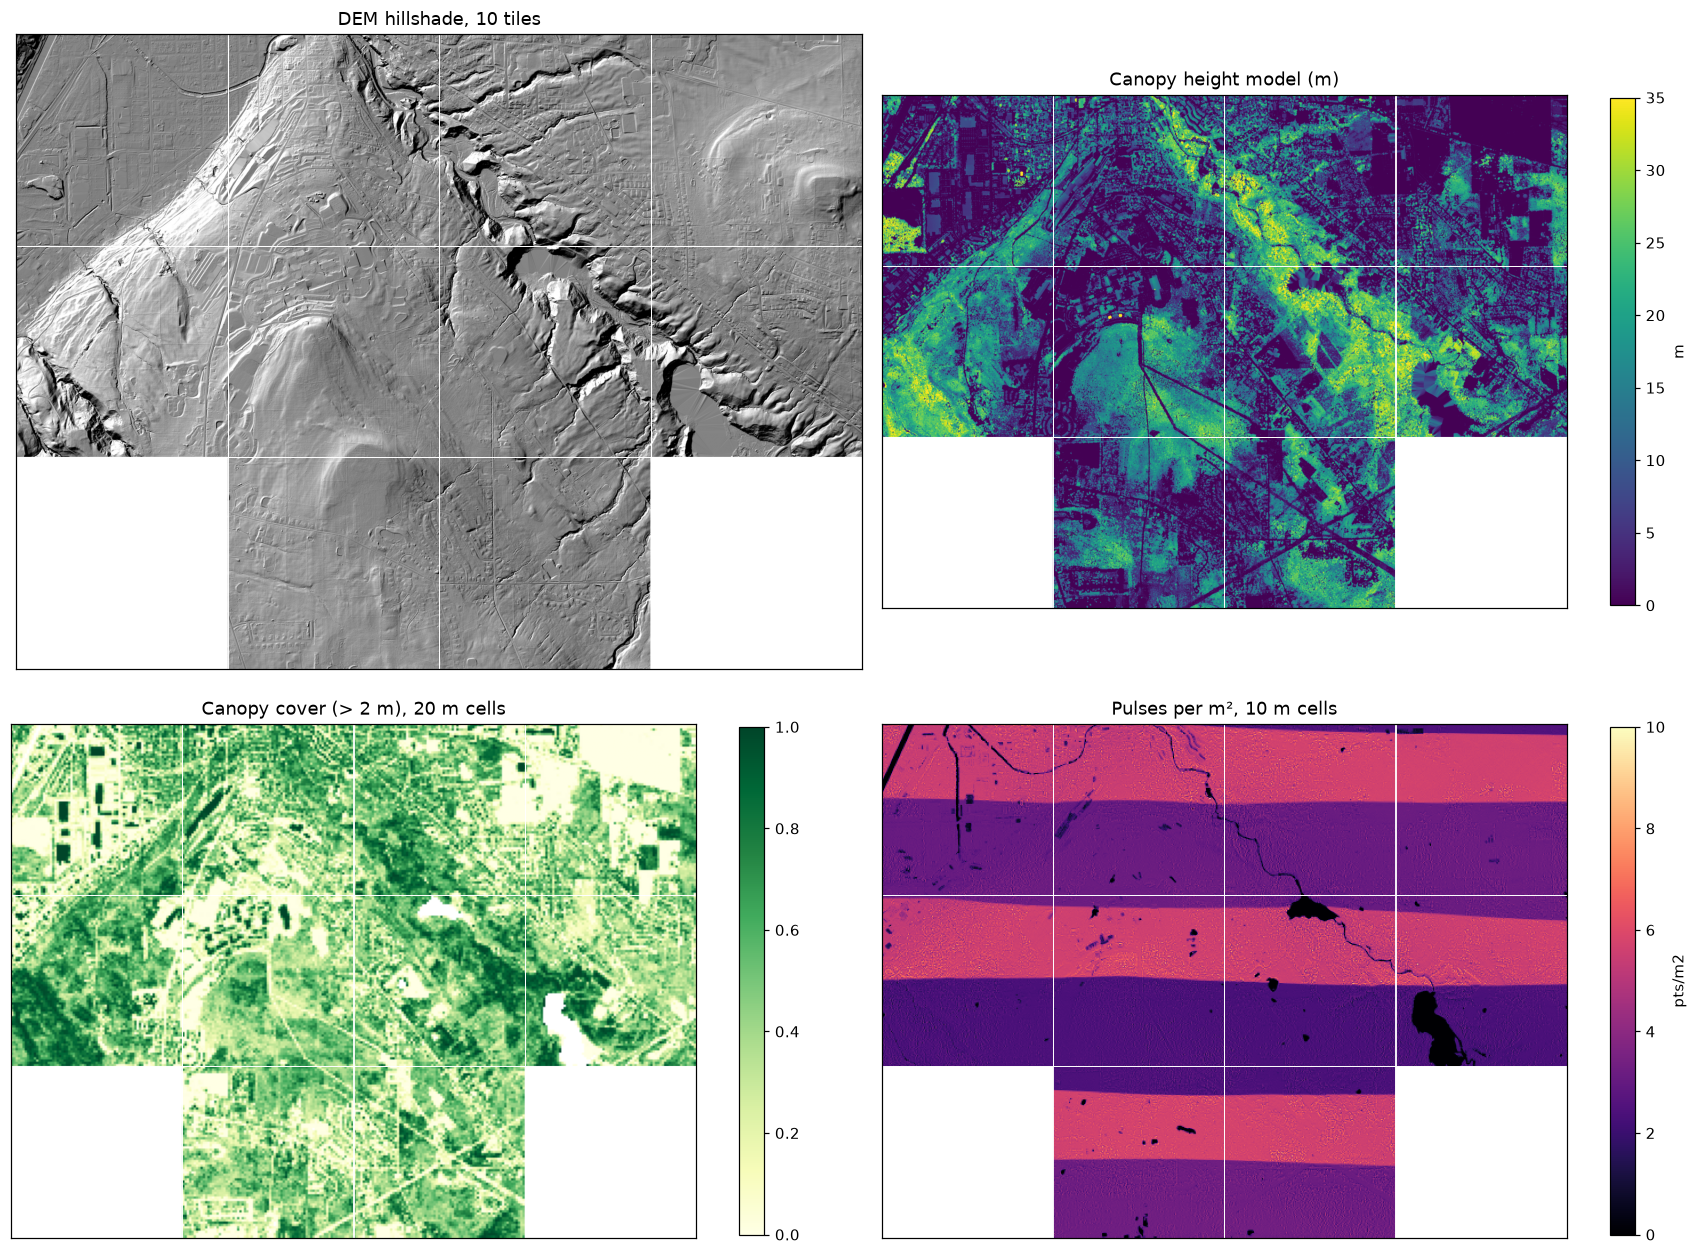

In [7]:
mosaic = {k: rs.lidar.merge_rasters([r[k] for r in results]) for k in ("dem", "dsm", "chm", "p95", "cover", "density")}  # mosaics
for k, v in mosaic.items():  # sizes
    print(f"{k:8s} {str(v.shape):14s} cell {abs(float(v.x[1] - v.x[0])):.0f} m | "  # summary line
          f"{float(np.isfinite(v.values).mean()):.1%} filled")  # shape and coverage

fig, axes = plt.subplots(2, 2, figsize=(16, 12))  # four panels
# map: DEM hillshade, 10 tiles
rs.viz.plot_raster(rs.lidar.hillshade(mosaic["dem"]), ax=axes[0, 0], cmap="gray", colorbar=False, title="DEM hillshade, 10 tiles")
# map: Canopy height model (m)
rs.viz.plot_raster(mosaic["chm"], ax=axes[0, 1], cmap="viridis", vmin=0, vmax=35, title="Canopy height model (m)")
# map: Canopy cover (> 2 m), 20 m cells
rs.viz.plot_raster(mosaic["cover"], ax=axes[1, 0], cmap="YlGn", vmin=0, vmax=1, title="Canopy cover (> 2 m), 20 m cells")
# map: Pulses per m², 10 m cells
rs.viz.plot_raster(mosaic["density"], ax=axes[1, 1], cmap="magma", vmin=0, vmax=10, title="Pulses per m², 10 m cells")
for a in axes.ravel():  # each panel
    index.boundary.plot(ax=a, color="white", lw=0.6); a.set_xticks([]); a.set_yticks([])  # tile outlines
plt.tight_layout(); plt.show()  # draw

The four products cover about 22 km² south of downtown Ithaca: the Six Mile Creek valley, South Hill and the farmland and forest around them. Density stripes follow the flight lines, and empty cells mark water surfaces, which return few laser echoes, and the corners not covered by the ten tiles. The white lines are the tile outlines. Within each tile the DEM was interpolated only from that tile's own ground points; with dense ground points and a 2 m grid this leaves no visible seams, but algorithms with larger neighbourhoods, such as ground filters, do react to tile edges, as the next section shows.


## Edge effects and buffered tiles

Many operations depend on neighbours: ground filters compare a point with its surroundings, interpolation fills gaps from nearby points, and tree detection looks for local maxima. At a tile edge these neighbours are missing. `rs.lidar.process_tiles` cuts a cloud into tiles of `size` m, gives each a `buffer` of extra points, runs a function on every buffered tile and trims the results back to the tile cores before merging them.

The experiment: a 1 km square that straddles the boundary between two delivery tiles is processed with SMRF ground filtering and a 1 m DEM on a grid of 250 m tiles, once without a buffer and once with a 40 m buffer, and both are compared with the same DEM computed on the whole square at once.


6,965,161 points in the 1 km square


,max |difference| (m),cells off by > 10 cm,seconds
"250 m tiles, buffer 0 m",11.9929,0.0068,13.7702
"250 m tiles, buffer 40 m",2.7889,0.0009,19.7701
whole square at once,0.0000,0.0000,34.6911


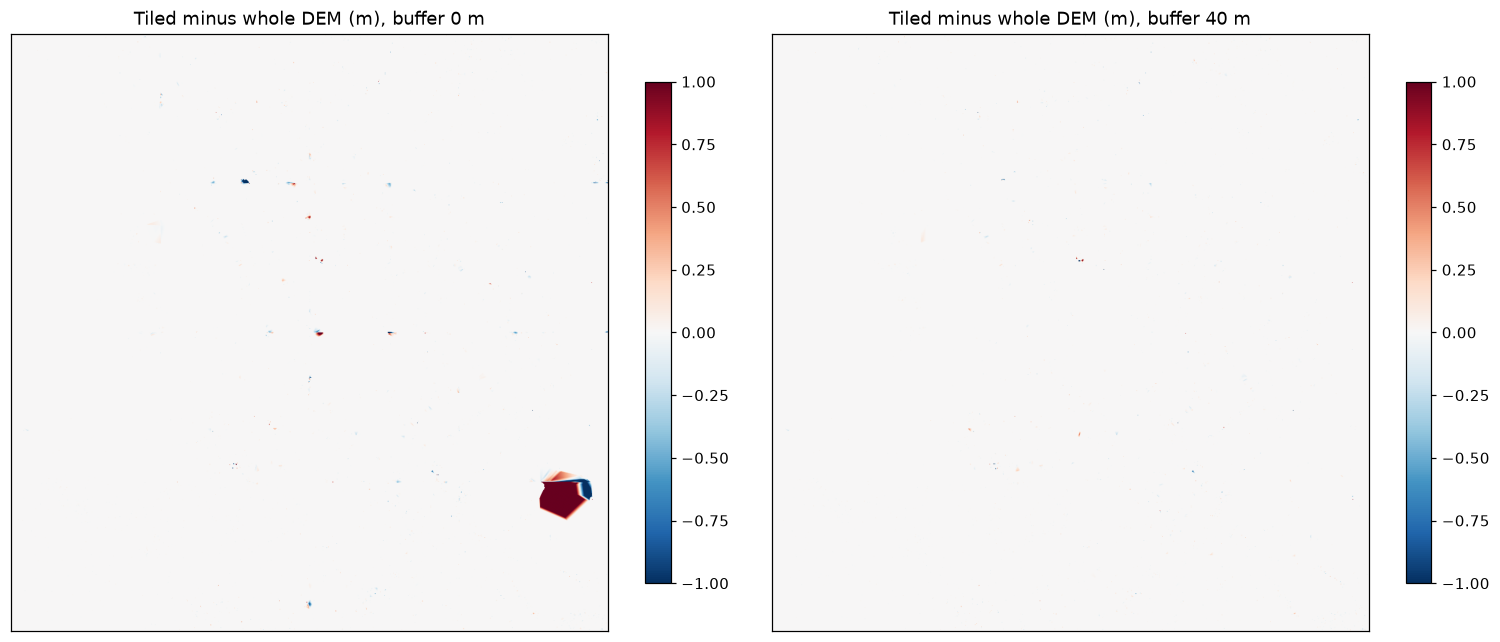

In [8]:
x_edge = 378000.0  # boundary between two delivery tiles
area = (x_edge - 500, 4697000.0, x_edge + 500, 4698000.0)  # a 1 km square across it
parts = [rs.lidar.read_las(DATA / "Ithaca" / f"u_{t}.las", fields=["classification"]).crop(*area)  # the two halves
         for t in ("3765069650", "3780069650")]
sq = rs.lidar.merge_pointclouds(parts).drop_noise()  # one cloud for the square
print(f"{len(sq):,} points in the 1 km square")  # size

def ground_dem(cloud):  # SMRF ground, then a 1 m DEM
    # SMRF ground, then a 1 m DEM
    return rs.lidar.dem(rs.lidar.smrf(cloud, cell=1.0, slope=0.15, window=18), 1.0)

t0 = time.perf_counter(); whole = ground_dem(sq); t_whole = time.perf_counter() - t0  # reference: all at once
runs = {}  # tiled results
for buf in (0, 40):  # without and with a buffer
    t0 = time.perf_counter()  # start the timer
    runs[buf] = rs.lidar.process_tiles(sq, ground_dem, size=250, buffer=buf, n_jobs=4)  # 16 tiles of 250 m
    runs[buf] = (runs[buf], time.perf_counter() - t0)  # keep the time
rows = {}  # one row per run
for buf, (dem_t, sec) in runs.items():  # each run
    d = dem_t.reindex_like(whole, method="nearest") - whole  # difference from the reference
    rows[f"250 m tiles, buffer {buf} m"] = {"max |difference| (m)": float(np.abs(d).max()),  # worst cell
                                            "cells off by > 10 cm": float((np.abs(d) > 0.1).mean()), "seconds": sec}
# reference row
rows["whole square at once"] = {"max |difference| (m)": 0.0, "cells off by > 10 cm": 0.0, "seconds": t_whole}
display(pd.DataFrame(rows).T.round(4))  # comparison

fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # two panels
for ax, buf in zip(axes, (0, 40)):  # each run
    d = runs[buf][0].reindex_like(whole, method="nearest") - whole  # difference map
    rs.viz.plot_raster(d, ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, title=f"Tiled minus whole DEM (m), buffer {buf} m")  # map
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

Without a buffer, the tiled DEM differs from the whole-square result at spots along the 250 m tile boundaries, where the ground filter and the interpolation see only half of their usual neighbourhood. In the south-east, one building cut by a tile boundary is classified differently as a whole and the DEM there is off by up to 12 m. With a 40 m buffer, wider than the 18 m SMRF window plus the interpolation distance, the share of cells that differ by more than 10 cm drops from about 0.7 % to under 0.1 %, and the remaining differences are isolated single cells. The rule is to make the buffer at least as wide as the largest neighbourhood used by any step of the pipeline. Note also that the tiled runs, executed in four threads, were faster than processing the whole square at once.


## Terrain derivatives on the GPU

With the CUDA backend selected (`rs.set_backend("cuda")`), GeoLattice raster functions run on CuPy arrays. The cell moves the 2 m DEM mosaic to the GPU and times five local derivatives against the CPU. The first GPU call of each function includes compiling its kernel, so the cell times a second, "warm" call. Point gridding in this version of GeoLattice runs on the CPU (the products above were gridded there).


In [9]:
dem_m = mosaic["dem"]  # 2 m DEM mosaic
ops = {"slope": lambda d: rs.lidar.slope(d), "hillshade": lambda d: rs.lidar.hillshade(d),  # local operations
       "curvature": lambda d: rs.lidar.curvature(d), "TRI": lambda d: rs.lidar.tri(d), "TPI (51 cells)": lambda d: rs.lidar.tpi(d, window=51)}
rows = {}  # timings
rs.set_backend("cpu")  # CPU first
for name, f in ops.items():  # each operation
    t0 = time.perf_counter(); cpu_out = f(dem_m); rows[name] = {"CPU (s)": time.perf_counter() - t0}  # CPU time
if "cuda" in rs.available_backends():  # GPU available
    import cupy as cp  # GPU arrays
    rs.set_backend("cuda")  # switch the backend
    dem_g = dem_m.copy(data=cp.asarray(dem_m.values))  # copy the DEM to GPU memory
    for name, f in ops.items():  # each operation
        f(dem_g); cp.cuda.Device().synchronize()  # first call compiles the kernel
        t0 = time.perf_counter(); out = f(dem_g); cp.cuda.Device().synchronize()  # warm call
        rows[name]["GPU (s)"] = time.perf_counter() - t0  # GPU time
    same = float(np.nanmax(np.abs(cp.asnumpy(rs.lidar.slope(dem_g).data) - rs.lidar.slope(dem_m.copy()).values)))  # check
    rs.set_backend("cpu")  # back to the CPU
    tab = pd.DataFrame(rows).T  # as a table
    tab["speed-up"] = tab["CPU (s)"] / tab["GPU (s)"]  # ratio
    display(tab.round(4))  # show it
    # summary line
    print(f"DEM {dem_m.shape} ({dem_m.size / 1e6:.1f} M cells) | largest CPU-GPU difference in slope: {same:.2e}°")
else:  # no GPU
    display(pd.DataFrame(rows).T.round(4)); print("No CUDA backend: GPU timings skipped.")  # show the table

,CPU (s),GPU (s),speed-up
slope,0.1436,0.0038,37.5227
hillshade,0.3011,0.0069,43.3375
curvature,0.0494,0.0038,12.8457
TRI,0.0908,0.0091,10.0202
TPI (51 cells),0.1194,0.0093,12.7914


DEM (2250, 3000) (6.8 M cells) | largest CPU-GPU difference in slope: 0.00e+00°


## Writing tiles

`rs.lidar.write_tiles` splits a cloud into smaller LAZ tiles, the usual way to hand processed point clouds to other software. The cell writes the 1 km square as 250 m LAZ tiles and compares the total size with the LAS source.


In [10]:
tile_dir = OUT / "ithaca_tiles_250m"  # output folder
paths = rs.lidar.write_tiles(sq, tile_dir, size=250, prefix="ithaca")  # 250 m LAZ tiles
laz_mb = sum(os.path.getsize(p) for p in paths) / 1e6  # their total size
las_mb = len(sq) * os.path.getsize(TILES[0]) / rs.lidar.las_info(TILES[0])["point_count"] / 1e6  # same points as LAS
# summary line
print(f"{len(paths)} tiles, e.g. {os.path.basename(paths[0])} | LAZ {laz_mb:.0f} MB vs about {las_mb:.0f} MB as LAS "
      f"({las_mb / laz_mb:.1f}x smaller)")  # sizes

16 tiles, e.g. ithaca_377500_4697000.laz | LAZ 31 MB vs about 251 MB as LAS (8.2x smaller)


## The end-to-end workflow

The chapter's notebooks together cover a complete LiDAR workflow. The cell writes the products of this notebook and assembles a checklist of the steps, the main `geolattice.rsense.lidar` functions for each, and where they are covered.


In [11]:
for k in ("dem", "dsm", "chm", "p95", "cover", "density"):  # each mosaic
    rs.write(mosaic[k].astype("float32"), OUT / f"ithaca_10tiles_{k}.tif")  # Cloud-Optimized GeoTIFF
index.to_file(OUT / "ithaca_tile_index.gpkg", driver="GPKG")  # tile index
print("written:", sorted(p.name for p in OUT.glob("ithaca_10tiles_*.tif")))  # products

workflow = pd.DataFrame([  # the workflow checklist
    ("1. Acquire", "LAS/LAZ tiles, COPC, EPT", "read_las (bounds, resolution), usgs_3dep_ept, read_pdal", "fundamentals"),
    ("2. Read and inspect", "CRS and units, classes, returns, density, cross-sections", "las_info, summary, reproject, density_map, cross_section", "fundamentals, processing"),
    ("3. Clean", "noise, outliers, crop, thin", "drop_noise, statistical_outlier_removal, clip_polygon, thin", "processing"),
    ("4. Classify ground", "SMRF, CSF, PMF and validation", "smrf, csf, pmf, classify_ground", "processing"),
    ("5. Build surfaces", "DEM, DSM, CHM, gap filling", "dem, dsm, chm, rasterize, fill_gaps", "processing"),
    ("6. Terrain and hydrology", "slope to geomorphons, flow, TWI, HAND", "slope, tpi, geomorphons, fill_depressions, flow_accumulation, twi, hand", "terrain and hydrology"),
    ("7. Normalise heights", "height above ground per point", "normalize_heights", "forest structure"),
    ("8a. Forest", "area-based metrics, trees, crowns", "grid_metrics, structure_metrics, detect_trees, segment_crowns", "forest structure"),
    ("8b. Buildings", "classification, footprints, roofs, solar", "classify_buildings, building_footprints, segment_roof_planes, solar_potential", "urban"),
    ("8c. All classes", "machine learning and deep learning", "point_feature_table, train_point_classifier, dl.pointnet", "point classification"),
    ("9. Cross-validate", "spaceborne LiDAR, field plots, checkpoints", "read_gedi_l2a, read_atl08, plot_metrics, vertical_accuracy", "spaceborne, forest, processing"),
    ("10. Scale and export", "tiles, buffers, parallel runs, GPU, COG/LAZ/GPKG", "process_files, process_tiles, merge_rasters, write_las, write_tiles, rs.write", "this notebook"),
], columns=["step", "what", "geolattice.rsense.lidar functions", "notebook"]).set_index("step")
workflow  # the checklist

written: ['ithaca_10tiles_chm.tif', 'ithaca_10tiles_cover.tif', 'ithaca_10tiles_dem.tif', 'ithaca_10tiles_density.tif', 'ithaca_10tiles_dsm.tif', 'ithaca_10tiles_p95.tif']


,what,geolattice.rsense.lidar functions,notebook
step,,,
1. Acquire,"LAS/LAZ tiles, COPC, EPT","read_las (bounds, resolution), usgs_3dep_ept, ...",fundamentals
2. Read and inspect,"CRS and units, classes, returns, density, cros...","las_info, summary, reproject, density_map, cro...","fundamentals, processing"
3. Clean,"noise, outliers, crop, thin","drop_noise, statistical_outlier_removal, clip_...",processing
4. Classify ground,"SMRF, CSF, PMF and validation","smrf, csf, pmf, classify_ground",processing
5. Build surfaces,"DEM, DSM, CHM, gap filling","dem, dsm, chm, rasterize, fill_gaps",processing
6. Terrain and hydrology,"slope to geomorphons, flow, TWI, HAND","slope, tpi, geomorphons, fill_depressions, flo...",terrain and hydrology
7. Normalise heights,height above ground per point,normalize_heights,forest structure
8a. Forest,"area-based metrics, trees, crowns","grid_metrics, structure_metrics, detect_trees,...",forest structure
8b. Buildings,"classification, footprints, roofs, solar","classify_buildings, building_footprints, segme...",urban


## Summary and exercises

**Key points**

- Index tiles from their headers first: footprints, counts, density and CRS cost almost nothing to read.
- Read only the fields a step needs, and stream very large files in chunks when only statistics are required.
- Grid each tile on its exact extent so the per-tile rasters mosaic without resampling.
- Neighbourhood operations need buffered tiles; the buffer must be wider than the largest window used, otherwise seams appear along tile edges.
- Tiles are independent, so they parallelise; memory, not CPU cores, usually limits how many run at once.
- Local raster operations run tens of times faster on a GPU; sequential hydrology stays on the CPU.

**`geolattice.rsense` functions used:** `rs.lidar.las_info`, `rs.lidar.read_las` (with `fields`), `rs.lidar.read_las_chunks`, `rs.lidar.process_files`, `rs.lidar.process_tiles`, `rs.lidar.merge_rasters`, `rs.lidar.merge_pointclouds`, `rs.lidar.write_tiles`, `rs.lidar.dem`, `rs.lidar.dsm`, `rs.lidar.chm`, `rs.lidar.smrf`, `rs.lidar.normalize_heights`, `rs.lidar.grid_metrics`, `rs.lidar.density_map`, `rs.lidar.hillshade`, `rs.lidar.slope`, `rs.lidar.curvature`, `rs.lidar.tri`, `rs.lidar.tpi`, `rs.set_backend`, `rs.available_backends`, `rs.write`, `rs.viz.plot_raster`.

**Exercises**

1. Run `process_files` with `n_jobs` of 1, 2, 5 and 10 and plot the wall-clock time. Where does the speed-up stop, and why?
2. Repeat the edge experiment with buffers of 10, 20 and 40 m. What is the smallest buffer that removes the seams for an 18 m SMRF window?
3. Add tree detection to `tile_products` and merge the treetops of all tiles. How would you avoid counting a tree twice where two tiles meet?
4. Compute flow accumulation on the 10-tile DEM mosaic and compare the stream network with the one from the four-tile DEM in the terrain notebook. What changes near the edges of the smaller area?
5. Estimate how long the `tile_products` pipeline would take for a county of 2,000 such tiles on this machine.
